<div style="background:#0B1F3A;color:white;padding:34px 30px;border-radius:14px">
<p style="margin:0;letter-spacing:3px;font-size:13px;color:#5EEAD4">MACHINE VISION · GROUP PROJECT</p>
<h1 style="margin:10px 0 6px 0;color:white;font-size:36px">Image Classification with Deep CNNs in Keras</h1>
<p style="margin:0;font-size:18px;color:#CBD5E1">A VGG-style plain CNN (Sequential API) versus a residual CNN (Functional API), trained from scratch on CIFAR-10</p>
</div>


## Table of contents

**Orientation**
- [How to run this notebook](#how-to-run)
- [Project at a glance](#glance)

**[Week 1 · Data pipeline and Model A](#week1)** (Checkpoint 1, 15%)
- [1.1 Environment and reproducibility](#w1-1) · [1.2 Load CIFAR-10](#w1-2) · [1.3 Stratified split](#w1-3) · [1.4 Sample images](#w1-4)
- [1.5 Preprocessing](#w1-5) · [1.6 Augmentation](#w1-6) · [1.7 Model A (Sequential)](#w1-7) · [1.8 Hand calculation](#w1-8) · [Checkpoint 1 summary](#cp1)

**[Week 2 · Train Model A, build Model B](#week2)** (Checkpoint 2, 20%)
- [2.1 Training protocol](#w2-1) · [2.2 Train Model A](#w2-2) · [2.3 Curves and metrics](#w2-3) · [2.4 Diagnosis](#w2-4)
- [2.5 Model B (Functional)](#w2-5) · [2.6 Verify Model B](#w2-6) · [2.7 Shape check at Add()](#w2-7) · [Checkpoint 2 summary](#cp2)

**[Week 3 · Train Model B, evaluate and compare](#week3)** (Checkpoint 3, 25%)
- [3.1 Train Model B](#w3-1) · [3.2 One-time test evaluation](#w3-2) · [3.3 Per-class metrics](#w3-3) · [3.4 Confusion matrices](#w3-4)
- [3.5 Comparison table](#w3-5) · [3.6 Error analysis](#w3-6) · [3.7 Gap from targets](#w3-7) · [3.8 Report draft outline](#w3-8) · [Checkpoint 3 summary](#cp3)

**[Week 4 · Final report, presentation and submission](#week4)** (40%)
- [4.1 Reproducibility check](#w4-1) · [4.2 Live prediction demo](#w4-2) · [4.3 Feedback appendix](#w4-3) · [4.4 Final report map](#w4-4)
- [4.5 Presentation plan](#w4-5) · [4.6 Bonus: CIFAR-100 transfer learning](#w4-6)

<a id="how-to-run"></a>
## How to run this notebook

1. In Colab choose **Runtime → Change runtime type → GPU**. Each model needs roughly 20–40 minutes on a free GPU.
2. Run the cells **top to bottom**. The notebook is organised in the same order as the four weekly checkpoints, so you can stop after any week and submit that part.
3. Three switches in cell 1.1 control long-running work:

| Switch | Default | Meaning |
|---|---|---|
| `QUICK_TEST` | `False` | `True` runs a 2-epoch dry run on 2,048 images. It writes to `quick_artifacts/` so it never overwrites real results. |
| `FORCE_RETRAIN` | `False` | `False` reuses a saved `model_*.keras` and its history file, which makes **Restart & Run All** fast after training. |
| `RUN_EXTENSION` | `False` | `True` runs the optional CIFAR-100 bonus in Week 4. |

**Files this notebook creates:** `model_a.keras`, `model_b.keras`, `history_model_a.json`, `history_model_b.json`, `test_results.json`, `probs_model_a.npy`, `probs_model_b.npy`, `model_b_architecture.png`.

<a id="glance"></a>
## Project at a glance

**Question.** How much does architecture (plain stack versus residual connections) change image-classification quality when data, training recipe and random seed are identical?

| | Model A | Model B |
|---|---|---|
| Style | VGG-style plain CNN | Residual CNN with skip connections |
| Keras API | `Sequential` (linear stack) | Functional (branches and `Add()` merges) |
| Convolutional layers | 6 (32, 32, 64, 64, 128, 128 kernels) | 10 (1 stem + 6 main-path + 3 shortcut) |
| Downsampling | 2×2 max pooling | Stride-2 convolutions |
| Before the classifier | Flatten (2,048 values) | Global average pooling (256 values) |
| Head | Dense 256 → Dense 10 | Dense 128 → Dense 10 |
| Parameters (total / trainable) | 815,914 / 815,018 | 1,246,154 / 1,243,402 |
| Target test accuracy | about 85% | about 88–90% |

**Grade structure.** Checkpoints 1–3 carry 60% (15% + 20% + 25%), the final package carries 40%, and the CIFAR-100 extension adds up to 5% bonus.

**Ground rules we follow throughout:** one fixed seed (42), one identical 45,000 / 5,000 / 10,000 split for both models, no pre-trained weights, tuning decisions on the validation set only, and a single test-set evaluation per model.

<a id="week1"></a>
<div style="background:#0F766E;color:white;padding:20px 26px;border-radius:12px">
<h1 style="margin:0;color:white">Week 1 · Data pipeline and Model A</h1>
<p style="margin:6px 0 0 0;font-size:16px">Checkpoint 1 · Tasks 1–3 · 15% of the grade</p>
</div>

### What we do this week

A deep-learning result is only as trustworthy as its data pipeline, so Week 1 builds the foundation before any training happens. We:

1. fix the environment and the random seed so every run is reproducible,
2. load CIFAR-10 and cut it into **train / validation / test** with a stratified split,
3. look at the data, then normalise it and define the augmentation layers,
4. implement **Model A** with the Sequential API and prove that its parameter count matches the brief exactly,
5. derive the output shapes and parameter counts of three layers by hand.

**Why parameter counts matter.** If `model.summary()` reports 815,914 parameters, the layer order, kernel counts, padding and batch normalisation all match the specification. A wrong count is a quick signal of a silent architecture mistake.


<a id="w1-1"></a>
### 1.1 Environment and reproducibility

**Why seed everything?** Weight initialisation, shuffling, dropout and augmentation are all random. With `keras.utils.set_random_seed(42)` Python, NumPy and the backend share one seed, so a re-run gives (nearly) the same numbers. GPU kernels can still add tiny non-determinism, so we compare accuracies, not bit patterns.

The three switches below are explained in *How to run this notebook*.

In [4]:
import os, json, time, random, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
from IPython.display import display, Image as IPImage

# ---- switches -------------------------------------------------------------
QUICK_TEST    = False   # True: 2-epoch dry run on 2,048 images (writes to quick_artifacts/)
FORCE_RETRAIN = False   # False: reuse saved models and histories if they exist
RUN_EXTENSION = False   # True: run the optional CIFAR-100 bonus in Week 4

# ---- fixed settings from the brief ------------------------------------------
SEED       = 42
BATCH_SIZE = 64
MAX_EPOCHS = 2 if QUICK_TEST else 60
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
COLORS = {"model_a": "#0F766E", "model_b": "#C2410C"}
DISPLAY_NAME = {"model_a": "Model A (VGG-style)", "model_b": "Model B (Residual)"}

WORKDIR = "quick_artifacts" if QUICK_TEST else "."
os.makedirs(WORKDIR, exist_ok=True)
def artifact(name): return os.path.join(WORKDIR, name)

keras.utils.set_random_seed(SEED)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

versions = pd.DataFrame({"component": ["Python", "TensorFlow", "Keras", "NumPy", "scikit-learn", "GPU"],
                         "version": [platform.python_version(), tf.__version__, keras.__version__, np.__version__,
                                     sklearn.__version__, str(len(tf.config.list_physical_devices("GPU"))) + " device(s)"]})
display(versions.set_index("component"))
if not tf.config.list_physical_devices("GPU"):
    warnings.warn("No GPU found. Training will be slow; switch the runtime to GPU.")
if QUICK_TEST:
    print("QUICK_TEST is ON: results are for debugging only.")

,version
component,
Python,3.11.18
TensorFlow,2.21.0
Keras,3.15.1
NumPy,2.4.6
scikit-learn,1.9.1
GPU,0 device(s)


C:\Users\fhv\AppData\Local\Temp\ipykernel_6904\1175001232.py:40: UserWarning: No GPU found. Training will be slow; switch the runtime to GPU.
  warnings.warn("No GPU found. Training will be slow; switch the runtime to GPU.")


<a id="w1-2"></a>
### 1.2 Load CIFAR-10

CIFAR-10 ships with Keras, so no manual download is needed. It arrives as 50,000 official training images and 10,000 official test images. Labels come as a column vector, so we flatten them to plain integers 0–9.

In [5]:
(x_full_raw, y_full), (x_test_raw, y_test) = keras.datasets.cifar10.load_data()
y_full, y_test = y_full.ravel(), y_test.ravel()

print("Official training set:", x_full_raw.shape, x_full_raw.dtype, "| labels:", y_full.shape)
print("Official test set    :", x_test_raw.shape, x_test_raw.dtype, "| labels:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1514s 9us/step
Official training set: (50000, 32, 32, 3) uint8 | labels: (50000,)
Official test set    : (10000, 32, 32, 3) uint8 | labels: (10000,)


<a id="w1-3"></a>
### 1.3 Stratified 45,000 / 5,000 / 10,000 split

| Subset | Images | Used for |
|---|---|---|
| Training | 45,000 | fitting the weights |
| Validation | 5,000 (500 per class) | early stopping, learning-rate schedule, model selection |
| Test | 10,000 (1,000 per class) | one final evaluation |

**Why a separate validation set?** Every decision we make while training (when to stop, which checkpoint to keep, when to lower the learning rate) is a form of tuning. If those decisions looked at the test set, the test score would be optimistic. The validation set absorbs all tuning so the test set stays an honest, one-time exam.

**Why stratify?** Stratification keeps the class proportions identical in every subset, so a difference between models cannot be caused by an unlucky class mix. The brief describes the validation set as 500 images per class; `train_test_split(..., stratify=labels, random_state=42)` produces exactly that, and the fixed seed gives both models the identical split.

,train,validation,test
class,,,
airplane,4500,500,1000
automobile,4500,500,1000
bird,4500,500,1000
cat,4500,500,1000
deer,4500,500,1000
dog,4500,500,1000
frog,4500,500,1000
horse,4500,500,1000
ship,4500,500,1000


Split verified: 45,000 / 5,000 / 10,000 with 500 validation and 1,000 test images per class.


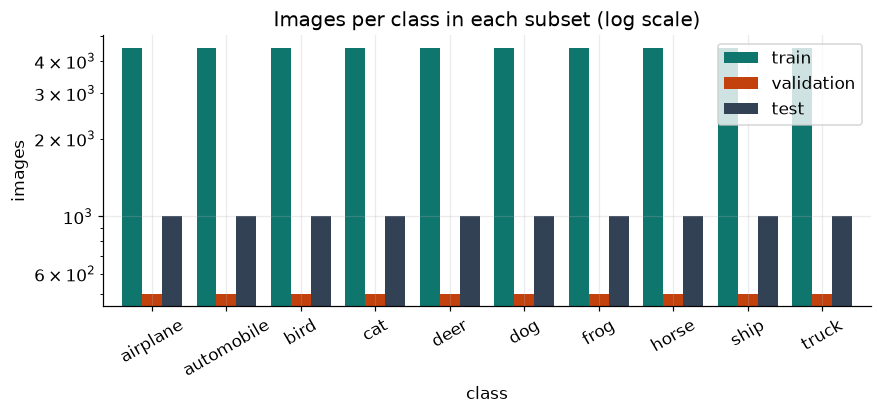

In [6]:
train_idx, val_idx = train_test_split(np.arange(len(y_full)), test_size=5000, stratify=y_full, random_state=SEED)

x_train_raw, y_train = x_full_raw[train_idx], y_full[train_idx]
x_val_raw,   y_val   = x_full_raw[val_idx],   y_full[val_idx]

counts = pd.DataFrame({"train": np.bincount(y_train), "validation": np.bincount(y_val), "test": np.bincount(y_test)},
                      index=pd.Index(CLASS_NAMES, name="class"))
counts.loc["TOTAL"] = counts.sum()
display(counts)

assert counts.loc["TOTAL"].tolist() == [45000, 5000, 10000]
assert (counts["validation"].iloc[:10] == 500).all() and (counts["test"].iloc[:10] == 1000).all()
print("Split verified: 45,000 / 5,000 / 10,000 with 500 validation and 1,000 test images per class.")

counts.iloc[:10].plot.bar(figsize=(9, 3.2), color=["#0F766E", "#C2410C", "#334155"], width=0.8, logy=True)
plt.title("Images per class in each subset (log scale)"); plt.ylabel("images"); plt.xticks(rotation=30); plt.show()

<a id="w1-4"></a>
### 1.4 Look at the data

Before modelling, we look at samples. At 32×32 pixels objects are tiny and often cropped or low-contrast, which explains why classes such as *cat* and *dog* will be hard for any model. Each row is one class, six random training images per row.

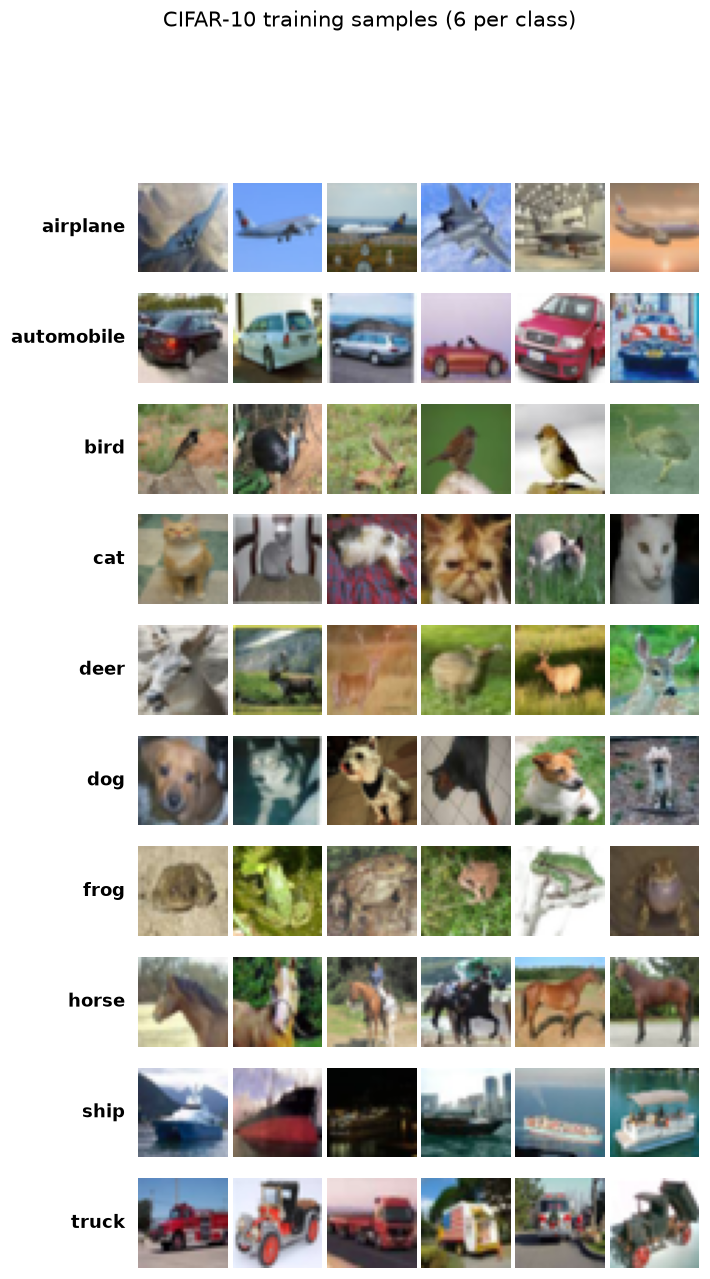

In [7]:
rng = np.random.default_rng(SEED)
n_per_class = 6
fig, axes = plt.subplots(10, n_per_class, figsize=(7.5, 13))
for c in range(10):
    picks = rng.choice(np.where(y_train == c)[0], n_per_class, replace=False)
    for j, i in enumerate(picks):
        ax = axes[c, j]; ax.imshow(x_train_raw[i]); ax.axis("off")
        if j == 0:
            ax.text(-0.15, 0.5, CLASS_NAMES[c], transform=ax.transAxes, ha="right", va="center", fontsize=12, fontweight="bold")
fig.suptitle("CIFAR-10 training samples (6 per class)", y=0.995, fontsize=14)
plt.subplots_adjust(left=0.22, wspace=0.05, hspace=0.05)
plt.show()

<a id="w1-5"></a>
### 1.5 Preprocessing

1. Cast pixels to `float32` and divide by 255, so every value lies in **[0, 1]**. Networks train more stably when inputs are small and similarly scaled.
2. Keep labels as **integers 0–9** and use *sparse* categorical cross-entropy. This avoids one-hot encoding and saves memory; the maths is identical.
3. Input tensor shape is `(32, 32, 3)`.

The checks below print shape, dtype, pixel range and label range for every subset.

In [8]:
def preprocess(x): return x.astype("float32") / 255.0

x_train, x_val, x_test = preprocess(x_train_raw), preprocess(x_val_raw), preprocess(x_test_raw)

checks = pd.DataFrame({
    "images shape": [x_train.shape, x_val.shape, x_test.shape],
    "dtype": [x_train.dtype, x_val.dtype, x_test.dtype],
    "min pixel": [x_train.min(), x_val.min(), x_test.min()],
    "max pixel": [x_train.max(), x_val.max(), x_test.max()],
    "label range": [(y_train.min(), y_train.max()), (y_val.min(), y_val.max()), (y_test.min(), y_test.max())],
}, index=["train", "validation", "test"])
display(checks)

for x, y in [(x_train, y_train), (x_val, y_val), (x_test, y_test)]:
    assert x.dtype == np.float32 and 0.0 <= x.min() and x.max() <= 1.0 and x.shape[1:] == (32, 32, 3)
    assert y.min() == 0 and y.max() == 9
print("Preprocessing verified.")

,images shape,dtype,min pixel,max pixel,label range
train,"(45000, 32, 32, 3)",float32,0.0,1.0,"(0, 9)"
validation,"(5000, 32, 32, 3)",float32,0.0,1.0,"(0, 9)"
test,"(10000, 32, 32, 3)",float32,0.0,1.0,"(0, 9)"


Preprocessing verified.


<a id="w1-6"></a>
### 1.6 Data augmentation (training only)

Augmentation shows the network slightly different versions of each training image every epoch, which acts as a regulariser: the model cannot simply memorise exact pixels.

| Layer | Effect |
|---|---|
| `RandomFlip("horizontal")` | mirrors the image left to right |
| `RandomTranslation(0.1, 0.1)` | shifts up to 10% (about ±3 px) |
| `RandomRotation(0.05)` | rotates up to 5% of a full turn (about ±18°) |

**Design decision.** The augmentation lives **inside each model** as Keras preprocessing layers. They run on the GPU, and Keras switches them off automatically at inference (`training=False`), so evaluation and predictions always see clean images. The demo below forces `training=True` to show what the network sees during training.

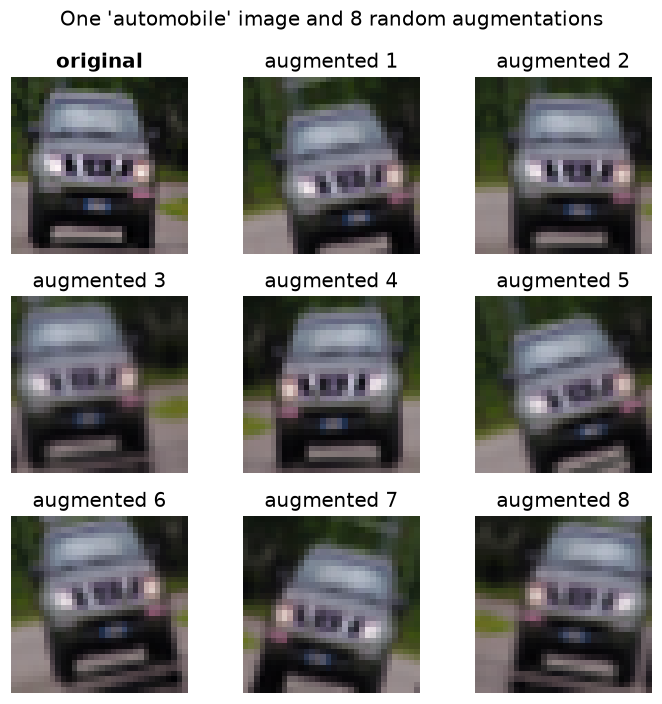

In [9]:
def build_augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomRotation(0.05),
    ], name="augmentation")

aug_demo = build_augmentation()
image = x_train[:1]
fig, axes = plt.subplots(3, 3, figsize=(6.5, 6.5))
axes[0, 0].imshow(image[0]); axes[0, 0].set_title("original", fontweight="bold")
for k, ax in enumerate(axes.ravel()[1:], 1):
    ax.imshow(np.clip(aug_demo(image, training=True)[0], 0, 1)); ax.set_title(f"augmented {k}")
for ax in axes.ravel(): ax.axis("off")
fig.suptitle(f"One '{CLASS_NAMES[y_train[0]]}' image and 8 random augmentations", fontsize=13)
plt.tight_layout(); plt.show()

<a id="w1-7"></a>
### 1.7 Model A: VGG-style CNN with the Sequential API

**The VGG idea.** Stack small 3×3 convolutions. Two 3×3 layers see the same 5×5 region as one 5×5 layer but with fewer parameters and an extra non-linearity. After every block we halve the spatial size (max pooling) and double the number of kernels, so the network trades spatial detail for richer features.

```
Input 32×32×3 → Augmentation
→ [Conv3×3 32 → BN → ReLU] ×2 → MaxPool → Dropout 0.25   (16×16×32)
→ [Conv3×3 64 → BN → ReLU] ×2 → MaxPool → Dropout 0.25   (8×8×64)
→ [Conv3×3 128 → BN → ReLU] ×2 → MaxPool → Dropout 0.25  (4×4×128)
→ Flatten (2,048) → Dense 256 ReLU → Dropout 0.5 → Dense 10 Softmax
```

**Why Sequential?** Every layer has exactly one input and one output, so a plain list of layers is enough. Model B will need branches, which `Sequential` cannot express.

**Why batch normalisation after every convolution?** It re-centres and re-scales activations, which allows larger learning rates and faster, more stable training.

In [10]:
def build_model_a():
    stack = [keras.Input(shape=(32, 32, 3)), build_augmentation()]
    conv_id = 0
    for block, filters in enumerate([32, 64, 128], start=1):
        for _ in range(2):
            conv_id += 1
            stack += [layers.Conv2D(filters, 3, strides=1, padding="same", name=f"conv{conv_id}"),
                      layers.BatchNormalization(name=f"bn{conv_id}"),
                      layers.ReLU(name=f"relu{conv_id}")]
        stack += [layers.MaxPooling2D(2, strides=2, name=f"pool{block}"),
                  layers.Dropout(0.25, name=f"drop{block}")]
    stack += [layers.Flatten(name="flatten"),
              layers.Dense(256, activation="relu", name="fc1"),
              layers.Dropout(0.5, name="drop_head"),
              layers.Dense(10, activation="softmax", name="fc2")]
    return keras.Sequential(stack, name="model_a_vgg")

def param_counts(model):
    total = model.count_params()
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    return total, trainable

keras.utils.set_random_seed(SEED)
model_a = build_model_a()
model_a.summary()

total_a, trainable_a = param_counts(model_a)
print(f"\nTotal parameters    : {total_a:,}   (brief: 815,914)")
print(f"Trainable parameters: {trainable_a:,}   (brief: 815,018)")
print(f"Non-trainable (batch-norm running mean/variance): {total_a - trainable_a:,}")
assert (total_a, trainable_a) == (815_914, 815_018), "Model A does not match Section 3"
print("Model A matches the brief.")

Model: "model_a_vgg"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (ReLU)                    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (ReLU)                    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop1 (Dropout)                 │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 16, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (ReLU)                    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 16, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (ReLU)                    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2 (Dropout)                 │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv5 (Conv2D)                  │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn5 (BatchNormalization)        │ (None, 8, 8, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu5 (ReLU)                    │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv6 (Conv2D)                  │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn6 (BatchNormalization)        │ (None, 8, 8, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu6 (ReLU)                    │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop3 (Dropout)                 │ (None, 4, 4, 128)      │             

 Total params: 815,914 (3.11 MB)

 Trainable params: 815,018 (3.11 MB)

 Non-trainable params: 896 (3.50 KB)


Total parameters    : 815,914   (brief: 815,914)
Trainable parameters: 815,018   (brief: 815,018)
Non-trainable (batch-norm running mean/variance): 896
Model A matches the brief.


<a id="w1-8"></a>
### 1.8 Hand calculation: output shapes and parameter counts

**Convolution.** With `same` padding and stride 1 the spatial size is unchanged; only the channel count changes to the number of kernels.

$$\text{params} = (k \times k \times C_{in} + 1) \times C_{out}$$

The `+ 1` is the bias of each kernel. **Dense layer:** $(\text{inputs} + 1) \times \text{units}$. Batch normalisation adds $2 \times C$ trainable values (scale and shift), plus $2 \times C$ non-trainable running statistics.

| Layer | Input | Calculation | Output shape | Parameters |
|---|---|---|---|---|
| Conv 1 | 32×32×3 | $(3\cdot3\cdot3+1)\cdot 32$ | 32×32×32 | 896 |
| Conv 3 | 16×16×32 | $(3\cdot3\cdot32+1)\cdot 64$ | 16×16×64 | 18,496 |
| FC1 | 2,048 | $(2048+1)\cdot 256$ | 256 | 524,544 |

The next cell repeats the arithmetic in code and checks it against what Keras reports.

In [11]:
def conv_params(k, c_in, c_out): return (k * k * c_in + 1) * c_out
def dense_params(n_in, units):   return (n_in + 1) * units

by_hand = {"conv1": conv_params(3, 3, 32), "conv3": conv_params(3, 32, 64), "fc1": dense_params(4 * 4 * 128, 256)}
rows = []
for name, formula in [("conv1", "(3*3*3 + 1) * 32"), ("conv3", "(3*3*32 + 1) * 64"), ("fc1", "(2048 + 1) * 256")]:
    layer = model_a.get_layer(name)
    rows.append({"layer": name, "formula": formula, "by hand": by_hand[name],
                 "Keras": layer.count_params(), "output shape": tuple(layer.output.shape[1:]),
                 "match": by_hand[name] == layer.count_params()})
display(pd.DataFrame(rows).set_index("layer"))
assert all(r["match"] for r in rows)

print("Batch norm after conv1:", 2 * 32, "trainable (scale + shift) +", 2 * 32, "running statistics")

,formula,by hand,Keras,output shape,match
layer,,,,,
conv1,(3*3*3 + 1) * 32,896,896,"(32, 32, 32)",True
conv3,(3*3*32 + 1) * 64,18496,18496,"(16, 16, 64)",True
fc1,(2048 + 1) * 256,524544,524544,"(256,)",True


Batch norm after conv1: 64 trainable (scale + shift) + 64 running statistics


<a id="cp1"></a>
### Checkpoint 1 summary

**Delivered**
- Reproducible set-up (seed 42, recorded versions) and a stratified 45,000 / 5,000 / 10,000 split with printed class counts.
- Sample grid, preprocessing checks and an augmentation demo.
- **Model A** built with `keras.Sequential`, matching the brief exactly: **815,914** total and **815,018** trainable parameters.
- Hand-derived shapes and parameter counts for Conv 1, Conv 3 and FC 1, verified against Keras.

**Take-aways**
- Splitting before looking at results is what keeps the later test score honest.
- Counting parameters is a cheap, strong test that an implementation follows its specification.

**Progress note (one page, edit before submitting).** *Write 4–6 sentences: what the group finished, anything that differed from the brief, and what is planned for Week 2.*

<a id="week2"></a>
<div style="background:#C2410C;color:white;padding:20px 26px;border-radius:12px">
<h1 style="margin:0;color:white">Week 2 · Train Model A, build Model B</h1>
<p style="margin:6px 0 0 0;font-size:16px">Checkpoint 2 · Tasks 4–5 · 20% of the grade</p>
</div>

### What we do this week

Week 1 produced a correct but untrained Model A. Week 2 turns it into a result and prepares the competitor:

1. define **one training recipe** (optimizer, loss, callbacks) that both models will share,
2. train Model A, save the best checkpoint as `model_a.keras`, and read the learning curves,
3. write a short diagnosis: overfitting, underfitting or a good fit,
4. implement **Model B** with the Functional API (residual blocks with 1×1 projection shortcuts and `Add()`),
5. verify Model B's parameter counts and tensor shapes, **without training it yet**.


<a id="w2-1"></a>
### 2.1 Training protocol (identical for both models)

Using the same recipe for both models means any difference in the results comes from the architecture, not from the training set-up.

| Setting | Value | Why |
|---|---|---|
| Optimizer | Adam, learning rate 1e-3 | adaptive step sizes; a robust default for CNNs |
| Loss | sparse categorical cross-entropy | integer labels, softmax outputs |
| Batch size | 64 | small enough for useful gradient noise, large enough for GPU efficiency |
| Maximum epochs | 60 | upper bound; early stopping usually ends sooner |
| Early stopping | monitor `val_loss`, patience 10, restore best weights | stops when validation loss stops improving and rolls back to the best weights |
| LR schedule | `ReduceLROnPlateau`: factor 0.5, patience 4, minimum 1e-5 | smaller steps once progress stalls help fine convergence |
| Checkpoint | best `val_accuracy`, `.keras` format | keeps the best model on disk |
| Seed | 42, re-set before each model is built | same initial conditions for both |

**Trade-off to be aware of.** Early stopping restores the best *validation-loss* weights in memory, while the checkpoint keeps the best *validation-accuracy* weights on disk. They are usually from nearby epochs, but not always the same one. We always evaluate the **saved file** in Week 3, so what we report is exactly what we hand in.

In [12]:
class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None): self._t0 = time.time()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.time() - self._t0)

def make_callbacks(name, timer):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5, verbose=1),
        keras.callbacks.ModelCheckpoint(artifact(f"{name}.keras"), monitor="val_accuracy", mode="max", save_best_only=True),
        timer,
    ]

def train_model(model, name, data=None):
    """Train with the Section 6 recipe, or reuse a saved model + history if they exist."""
    model_path, hist_path = artifact(f"{name}.keras"), artifact(f"history_{name}.json")
    if (not FORCE_RETRAIN) and os.path.exists(model_path) and os.path.exists(hist_path):
        print(f"Found saved {name}; loading its history (set FORCE_RETRAIN = True to retrain).")
        with open(hist_path) as f: return json.load(f)
    xt, yt, xv, yv = data if data is not None else (x_train, y_train, x_val, y_val)
    if QUICK_TEST: xt, yt = xt[:2048], yt[:2048]
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    timer = EpochTimer()
    h = model.fit(xt, yt, validation_data=(xv, yv), batch_size=BATCH_SIZE, epochs=MAX_EPOCHS,
                  callbacks=make_callbacks(name, timer), verbose=2)
    hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    hist["epoch_time"] = [float(t) for t in timer.times]
    with open(hist_path, "w") as f: json.dump(hist, f)
    return hist

def summarize_history(hist):
    va = np.array(hist["val_accuracy"]); be = int(va.argmax())
    return {"epochs run": len(va), "best val accuracy": float(va[be]), "epoch of best val accuracy": be + 1,
            "train accuracy at that epoch": hist["accuracy"][be],
            "best val loss": float(min(hist["val_loss"])), "epoch of best val loss": int(np.argmin(hist["val_loss"])) + 1,
            "mean time per epoch (s)": float(np.mean(hist["epoch_time"]))}

def plot_history(hist, name):
    s = summarize_history(hist); e = np.arange(1, len(hist["loss"]) + 1); c = COLORS[name]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, key, title in [(axes[0], "accuracy", "Accuracy"), (axes[1], "loss", "Loss")]:
        ax.plot(e, hist[key], color=c, lw=2, label="training")
        ax.plot(e, hist["val_" + key], color=c, lw=2, ls="--", label="validation")
        ax.axvline(s["epoch of best val accuracy"], color="grey", ls=":", label="best val accuracy")
        ax.set_title(f"{DISPLAY_NAME[name]}: {title}"); ax.set_xlabel("epoch"); ax.legend()
    plt.tight_layout(); plt.show()

def diagnose(hist):
    s = summarize_history(hist); gap = s["train accuracy at that epoch"] - s["best val accuracy"]
    if gap > 0.05: verdict = "overfitting (training accuracy clearly above validation accuracy)"
    elif s["train accuracy at that epoch"] < 0.75 and s["best val accuracy"] < 0.75: verdict = "underfitting (both accuracies are low)"
    else: verdict = "a good fit (train and validation accuracy are close and high)"
    return (f"Train - validation accuracy gap at the best epoch: {gap * 100:+.1f} points.\n"
            f"Automatic reading: {verdict}.\n"
            "Note: augmentation and dropout are active during training, so training accuracy can sit BELOW validation accuracy.")
print("Training utilities ready.")

Training utilities ready.


<a id="w2-2"></a>
### 2.2 Train Model A

We re-seed and rebuild the model so its initial weights do not depend on what ran earlier in the session. Training prints one line per epoch; learning-rate drops and early stopping are announced by the callbacks.

In [13]:
keras.utils.set_random_seed(SEED)
model_a = build_model_a()
hist_a = train_model(model_a, "model_a")
print("Saved best model:", artifact("model_a.keras"))

Epoch 1/60
704/704 - 54s - 76ms/step - accuracy: 0.3090 - loss: 1.8614 - val_accuracy: 0.4278 - val_loss: 1.5672 - learning_rate: 0.0010
Epoch 2/60
704/704 - 49s - 69ms/step - accuracy: 0.4204 - loss: 1.5694 - val_accuracy: 0.4154 - val_loss: 1.7971 - learning_rate: 0.0010
Epoch 3/60
704/704 - 49s - 70ms/step - accuracy: 0.4851 - loss: 1.4204 - val_accuracy: 0.4812 - val_loss: 1.4063 - learning_rate: 0.0010
Epoch 4/60
704/704 - 49s - 70ms/step - accuracy: 0.5349 - loss: 1.3126 - val_accuracy: 0.5862 - val_loss: 1.1095 - learning_rate: 0.0010
Epoch 5/60
704/704 - 56s - 80ms/step - accuracy: 0.5687 - loss: 1.2251 - val_accuracy: 0.6160 - val_loss: 1.1124 - learning_rate: 0.0010
Epoch 6/60
704/704 - 52s - 74ms/step - accuracy: 0.5995 - loss: 1.1499 - val_accuracy: 0.6146 - val_loss: 1.1327 - learning_rate: 0.0010
Epoch 7/60
704/704 - 53s - 75ms/step - accuracy: 0.6214 - loss: 1.0949 - val_accuracy: 0.6476 - val_loss: 0.9908 - learning_rate: 0.0010
Epoch 8/60
704/704 - 53s - 75ms/step - ac

<a id="w2-3"></a>
### 2.3 Learning curves and key numbers

How to read the curves: **training** curves show how well the model fits data it learns from; **validation** curves show generalisation. The grey dotted line marks the epoch with the best validation accuracy, which is the checkpoint we keep.

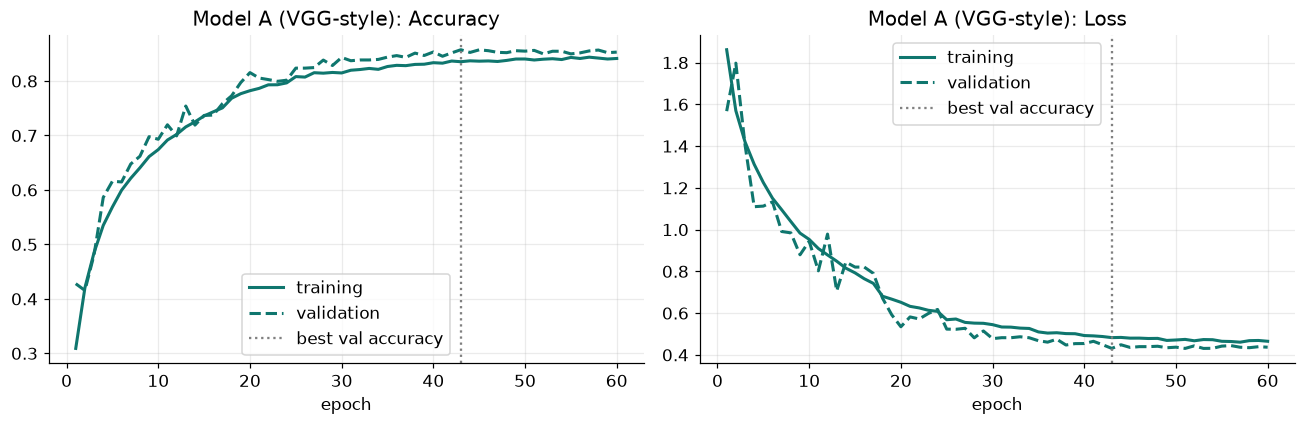

,Model A
epochs run,60.000000
best val accuracy,0.857400
epoch of best val accuracy,43.000000
train accuracy at that epoch,0.835378
best val loss,0.430766
epoch of best val loss,53.000000
mean time per epoch (s),51.650386


In [14]:
plot_history(hist_a, "model_a")
summary_a = summarize_history(hist_a)
display(pd.Series(summary_a, name="Model A").to_frame())

<a id="w2-4"></a>
### 2.4 Diagnosis of Model A's training curves

The cell below gives an automatic first reading from the numbers. Use it together with the plots to write your own paragraph.

In [15]:
print(diagnose(hist_a))

Train - validation accuracy gap at the best epoch: -2.2 points.
Automatic reading: a good fit (train and validation accuracy are close and high).
Note: augmentation and dropout are active during training, so training accuracy can sit BELOW validation accuracy.


**Our diagnosis**

> *Model A fits reasonably well, with slight signs of overfitting. The gap between training accuracy (83.54%) and best validation accuracy (85.74%) is small. Validation loss reaches its minimum at epoch 53, showing continued improvement. Data augmentation and dropout help reduce overfitting but make training more challenging. The learning rate reduction helps improve performance. Overall, more epochs or model capacity are unlikely to provide significant improvements.*

<a id="w2-5"></a>
### 2.5 Model B: residual CNN with the Functional API

**The problem residual connections solve.** In a plain deep network, gradients must travel through every layer, and optimisation gets harder as depth grows. A residual block lets the signal take a shortcut: the block learns a *correction* to its input instead of a whole new representation, i.e. $\text{output} = F(x) + x$.

**Why the Functional API?** The tensor `x` is used twice (main path and shortcut) and the two results are merged by `Add()`. That is a graph, not a list, so `Sequential` cannot express it.

```
                 ┌─ Conv3×3 (stride s) → BN → ReLU → Conv3×3 (stride 1) → BN ─┐
 Input x ────────┤                                                             ├─ Add → ReLU
                 └─ Conv1×1 (stride s) → BN ──────────────────────────────────┘
```

**Why a 1×1 projection with the same stride?** `Add()` sums tensors element by element, so both branches must end with identical shapes. The main path changes channels (and halves the size when `s = 2`); the 1×1 convolution on the shortcut changes channels the same way, and using the same stride makes the spatial size match.

| Part | Kernels | Stride | Output |
|---|---|---|---|
| Stem conv 3×3 | 32 | 1 | 32×32×32 |
| Residual block 1 | 64 | 1 | 32×32×64 |
| Residual block 2 | 128 | 2 | 16×16×128 |
| Residual block 3 | 256 | 2 | 8×8×256 |
| Global average pooling | none | none | 256 |
| Dense 128 (ReLU, dropout 0.3) → Dense 10 (softmax) | none | none | 10 |

In [16]:
def residual_block(x, filters, stride, name, shape_log=None):
    # main path
    main = layers.Conv2D(filters, 3, strides=stride, padding="same", name=f"{name}_conv_a")(x)
    main = layers.BatchNormalization(name=f"{name}_bn_a")(main)
    main = layers.ReLU(name=f"{name}_relu_a")(main)
    main = layers.Conv2D(filters, 3, strides=1, padding="same", name=f"{name}_conv_b")(main)
    main = layers.BatchNormalization(name=f"{name}_bn_b")(main)
    # shortcut path: 1x1 projection with the SAME stride as the main path
    shortcut = layers.Conv2D(filters, 1, strides=stride, padding="same", name=f"{name}_shortcut_conv")(x)
    shortcut = layers.BatchNormalization(name=f"{name}_shortcut_bn")(shortcut)
    if shape_log is not None:
        shape_log.append({"block": name, "main path": tuple(main.shape[1:]), "shortcut": tuple(shortcut.shape[1:])})
    out = layers.Add(name=f"{name}_add")([main, shortcut])
    return layers.ReLU(name=f"{name}_out")(out)

def build_model_b(num_classes=10, shape_log=None):
    inputs = keras.Input(shape=(32, 32, 3), name="image")
    x = build_augmentation()(inputs)
    x = layers.Conv2D(32, 3, strides=1, padding="same", name="stem_conv")(x)
    x = layers.BatchNormalization(name="stem_bn")(x)
    x = layers.ReLU(name="stem_relu")(x)
    x = residual_block(x, 64, 1, "block1", shape_log)
    x = residual_block(x, 128, 2, "block2", shape_log)
    x = residual_block(x, 256, 2, "block3", shape_log)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(128, activation="relu", name="fc1")(x)
    x = layers.Dropout(0.3, name="drop_head")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="fc2")(x)
    return keras.Model(inputs, outputs, name="model_b_residual")

SHAPE_LOG = []
keras.utils.set_random_seed(SEED)
model_b = build_model_b(10, SHAPE_LOG)
model_b.summary()

Model: "model_b_residual"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 32, 32, 3) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 32, 32, 3) │          0 │ image[0][0]       │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 32, 32,    │        896 │ augmentation[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 32, 32,    │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_relu (ReLU)    │ (None, 32, 32,    │          0 │ stem_bn[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv_a       │ (None, 32, 32,    │     18,496 │ stem_relu[0][0]   │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_bn_a         │ (None, 32, 32,    │        256 │ block1_conv_a[0]… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_relu_a       │ (None, 32, 32,    │          0 │ block1_bn_a[0][0] │
│ (ReLU)              │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv_b       │ (None, 32, 32,    │     36,928 │ block1_relu_a[0]… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_shortcut_co… │ (None, 32, 32,    │      2,112 │ stem_relu[0][0]   │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_bn_b         │ (None, 32, 32,    │        256 │ block1_conv_b[0]… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_shortcut_bn  │ (None, 32, 32,    │        256 │ block1_shortcut_… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_add (Add)    │ (None, 32, 32,    │          0 │ block1_bn_b[0][0… │
│                     │ 64)               │            │ block1_shortcut_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_out (ReLU)   │ (None, 32, 32,    │          0 │ block1_add[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv_a       │ (None, 16, 16,    │     73,856 │ block1_out[0][0]  │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_bn_a         │ (None, 16, 16,    │        512 │ block2_conv_a[0]… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_relu_a       │ (None, 16, 16,    │          0 │ block2_bn_a[0][0] │
│ (ReLU)              │ 128)              │            │                 

 Total params: 1,246,154 (4.75 MB)

 Trainable params: 1,243,402 (4.74 MB)

 Non-trainable params: 2,752 (10.75 KB)

<a id="w2-6"></a>
### 2.6 Verify Model B against Section 4

We check the totals, count the convolutions, and export the graph with `plot_model`. The graph image is the architecture diagram for the report.

In [28]:
import os
import keras
from IPython.display import Image as IPImage, display

# Make Graphviz available to the current Python kernel
graphviz_bin = r"C:\Program Files (x86)\Graphviz\bin"
os.environ["PATH"] = graphviz_bin + os.pathsep + os.environ["PATH"]

# Validate Model B
total_b, trainable_b = param_counts(model_b)
n_conv = sum(isinstance(l, layers.Conv2D) for l in model_b.layers)

print(f"Total parameters    : {total_b:,}   (brief: 1,246,154)")
print(f"Trainable parameters: {trainable_b:,}   (brief: 1,243,402)")
print(f"Convolution layers  : {n_conv}   (brief: 10 = 1 stem + 6 main path + 3 shortcut)")

assert (total_b, trainable_b) == (1_246_154, 1_243_402) and n_conv == 10, \
    "Model B does not match Section 4"

print("Model B matches the brief.")

# Generate architecture visualization
try:
    output_file = artifact("model_b_architecture.png")

    keras.utils.plot_model(
        model_b,
        to_file=output_file,
        show_shapes=True,
        show_layer_names=True,
        dpi=70
    )

    display(IPImage(filename=output_file))
    print("Architecture image generated successfully:", output_file)

except Exception as err:
    print("Architecture visualization failed:", type(err).__name__, str(err))


Total parameters    : 1,246,154   (brief: 1,246,154)
Trainable parameters: 1,243,402   (brief: 1,243,402)
Convolution layers  : 10   (brief: 10 = 1 stem + 6 main path + 3 shortcut)
Model B matches the brief.
You must install pydot (`pip install pydot`) for `plot_model` to work.
Architecture visualization failed: FileNotFoundError [Errno 2] No such file or directory: '.\\model_b_architecture.png'


<a id="w2-7"></a>
### 2.7 Shape check just before each `Add()`

The table lists the main-path and shortcut shapes entering every `Add()`. They must be identical.

In [29]:
shape_df = pd.DataFrame(SHAPE_LOG).set_index("block")
shape_df["equal"] = shape_df["main path"] == shape_df["shortcut"]
display(shape_df)
assert shape_df["equal"].all()
print("All three Add() layers receive matching shapes.")

,main path,shortcut,equal
block,,,
block1,"(32, 32, 64)","(32, 32, 64)",True
block2,"(16, 16, 128)","(16, 16, 128)",True
block3,"(8, 8, 256)","(8, 8, 256)",True


All three Add() layers receive matching shapes.


**Why the 1×1 shortcut needs the same stride as the main path.**
The first convolution of blocks 2 and 3 uses stride 2, which halves the height and width (32→16, 16→8). If the shortcut kept stride 1 it would still be 32×32 (or 16×16) while the main path is already half that size, so `Add()` would raise a shape error: element-wise addition needs identical shapes. Giving the 1×1 projection the same stride shrinks the shortcut in step with the main path, and its 128 (or 256) kernels also match the channel count. In block 1 the stride is 1, but the projection is still needed because the channels change from 32 to 64.

<a id="cp2"></a>
### Checkpoint 2 summary

**Delivered**
- A shared, fully specified training recipe (Adam 1e-3, batch 64, early stopping, learning-rate schedule, checkpointing, seed 42).
- **Model A trained**, best checkpoint saved as `model_a.keras`, curves plotted, best validation accuracy, its epoch and time per epoch reported, and a written diagnosis.
- **Model B built** with the Functional API: **1,246,154** total and **1,243,402** trainable parameters, 10 convolutional layers, a `plot_model` diagram and verified shapes at every `Add()`.
- The test set has **not** been touched.

**Take-aways**
- A fixed recipe turns the later comparison into a fair experiment.
- Residual blocks only work if both branches end with the same shape, which is why the shortcut copies the main path's stride.


<a id="week3"></a>
<div style="background:#0F766E;color:white;padding:20px 26px;border-radius:12px">
<h1 style="margin:0;color:white">Week 3 · Train Model B, evaluate and compare</h1>
<p style="margin:6px 0 0 0;font-size:16px">Checkpoint 3 · Tasks 6–7 · 25% of the grade</p>
</div>

### What we do this week

Both architectures are now defined. Week 3 settles the comparison:

1. train **Model B** with exactly the same recipe as Model A and save `model_b.keras`,
2. **freeze** both models and run the **one-time test evaluation** (test accuracy and loss),
3. produce per-class precision, recall and F1, and a 10×10 confusion matrix for each model, naming the most-confused class pairs,
4. build the **comparison table** (accuracy, loss, parameters, time per epoch, epochs to best validation score),
5. study misclassified images, compare with the expected targets and outline the report.


<a id="w3-1"></a>
### 3.1 Train Model B (same settings as Model A)

We re-seed, rebuild Model B and call the very same `train_model` function, so every setting (optimizer, batch size, callbacks, seed) is identical to Model A.

Epoch 1/60
704/704 - 219s - 310ms/step - accuracy: 0.4452 - loss: 1.5267 - val_accuracy: 0.4728 - val_loss: 1.4177 - learning_rate: 0.0010
Epoch 2/60
704/704 - 210s - 299ms/step - accuracy: 0.5782 - loss: 1.1826 - val_accuracy: 0.2990 - val_loss: 2.8554 - learning_rate: 0.0010
Epoch 3/60
704/704 - 215s - 305ms/step - accuracy: 0.6299 - loss: 1.0451 - val_accuracy: 0.5822 - val_loss: 1.2574 - learning_rate: 0.0010
Epoch 4/60
704/704 - 235s - 334ms/step - accuracy: 0.6716 - loss: 0.9361 - val_accuracy: 0.5152 - val_loss: 1.6503 - learning_rate: 0.0010
Epoch 5/60
704/704 - 198s - 282ms/step - accuracy: 0.7036 - loss: 0.8521 - val_accuracy: 0.5558 - val_loss: 1.6304 - learning_rate: 0.0010
Epoch 6/60
704/704 - 189s - 268ms/step - accuracy: 0.7290 - loss: 0.7856 - val_accuracy: 0.6720 - val_loss: 1.0275 - learning_rate: 0.0010
Epoch 7/60
704/704 - 177s - 251ms/step - accuracy: 0.7478 - loss: 0.7302 - val_accuracy: 0.7286 - val_loss: 0.8050 - learning_rate: 0.0010
Epoch 8/60
704/704 - 175s -

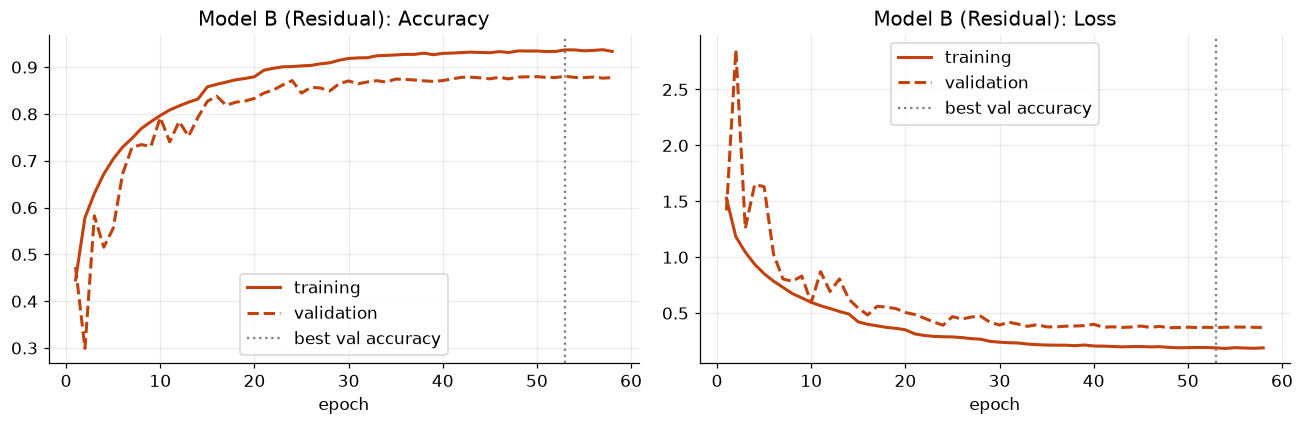

,Model A,Model B
epochs run,60.000000,58.000000
best val accuracy,0.857400,0.880400
epoch of best val accuracy,43.000000,53.000000
train accuracy at that epoch,0.835378,0.936800
best val loss,0.430766,0.369191
epoch of best val loss,53.000000,48.000000
mean time per epoch (s),51.650386,178.997117


Train - validation accuracy gap at the best epoch: +5.6 points.
Automatic reading: overfitting (training accuracy clearly above validation accuracy).
Note: augmentation and dropout are active during training, so training accuracy can sit BELOW validation accuracy.


In [30]:
keras.utils.set_random_seed(SEED)
model_b = build_model_b(10)
hist_b = train_model(model_b, "model_b")
plot_history(hist_b, "model_b")
summary_b = summarize_history(hist_b)
display(pd.DataFrame({"Model A": summarize_history(hist_a), "Model B": summary_b}))
print(diagnose(hist_b))

<a id="w3-2"></a>
### 3.2 Freeze both models, then evaluate on the test set once

1. Load each **saved file** (not the in-memory model), so the reported numbers describe exactly what we submit.
2. Set `trainable = False`: from now on nothing is tuned.
3. Call `model.evaluate` for test loss and accuracy, and `model.predict` once to keep the class probabilities for all later analysis (reports, confusion matrices, error analysis).

`evaluate` and `predict` read the same 10,000 images once each; no weights change and no decisions are made from them, so this still counts as a single evaluation.

In [31]:
RESULTS_PATH = artifact("test_results.json")
TEST_RESULTS = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}

def evaluate_once(name):
    if name in TEST_RESULTS and os.path.exists(artifact(f"probs_{name}.npy")):
        print(f"{name}: test set already evaluated; using cached results (not evaluating again).")
        return
    model = keras.models.load_model(artifact(f"{name}.keras"))
    model.trainable = False
    loss, acc = model.evaluate(x_test, y_test, batch_size=256, verbose=0)
    probs = model.predict(x_test, batch_size=256, verbose=0)
    np.save(artifact(f"probs_{name}.npy"), probs)
    TEST_RESULTS[name] = {"test_loss": float(loss), "test_accuracy": float(acc)}
    with open(RESULTS_PATH, "w") as f: json.dump(TEST_RESULTS, f, indent=2)
    print(f"{name}: evaluated on the test set.")

for name in ["model_a", "model_b"]:
    evaluate_once(name)

probs = {n: np.load(artifact(f"probs_{n}.npy")) for n in ["model_a", "model_b"]}
y_pred = {n: p.argmax(1) for n, p in probs.items()}
display(pd.DataFrame(TEST_RESULTS).T.rename(columns={"test_loss": "test loss", "test_accuracy": "test accuracy"})
        .style.format({"test loss": "{:.4f}", "test accuracy": "{:.2%}"}))

model_a: evaluated on the test set.
model_b: evaluated on the test set.


,test loss,test accuracy
model_a,0.4831,84.25%
model_b,0.3865,87.64%


<a id="w3-3"></a>
### 3.3 Per-class precision, recall and F1

- **Precision**: of the images the model labelled *cat*, how many really are cats?
- **Recall**: of all real cats, how many did the model find?
- **F1**: the harmonic mean of the two, which punishes a model that is strong on only one.

Overall accuracy hides class-level weaknesses; this report shows them.

Model A (VGG-style)
              precision    recall  f1-score   support

    airplane      0.856     0.878     0.867      1000
  automobile      0.923     0.945     0.934      1000
        bird      0.870     0.745     0.803      1000
         cat      0.775     0.621     0.690      1000
        deer      0.834     0.818     0.826      1000
         dog      0.817     0.712     0.761      1000
        frog      0.734     0.950     0.828      1000
       horse      0.850     0.907     0.878      1000
        ship      0.922     0.907     0.914      1000
       truck      0.859     0.942     0.899      1000

    accuracy                          0.843     10000
   macro avg      0.844     0.842     0.840     10000
weighted avg      0.844     0.843     0.840     10000

Model B (Residual)
              precision    recall  f1-score   support

    airplane      0.895     0.876     0.885      1000
  automobile      0.928     0.957     0.942      1000
        bird      0.798     0.843     0

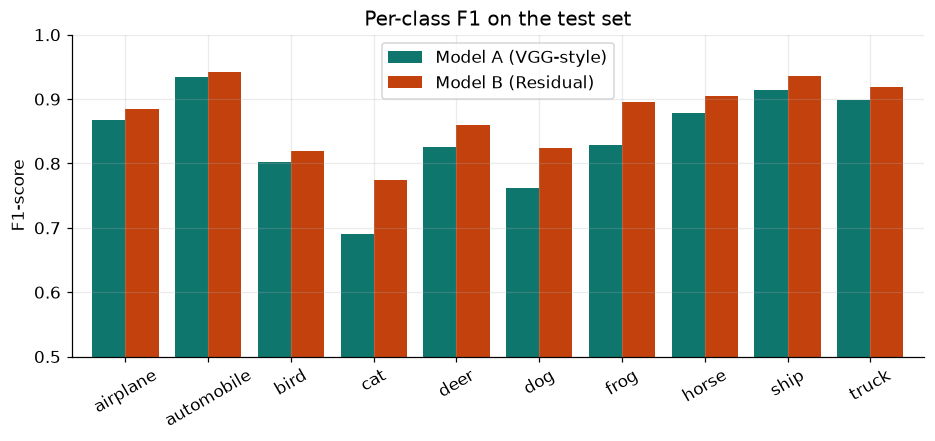

In [32]:
for n in ["model_a", "model_b"]:
    print("=" * 70); print(DISPLAY_NAME[n]); print("=" * 70)
    print(classification_report(y_test, y_pred[n], target_names=CLASS_NAMES, digits=3))

f1 = pd.DataFrame({DISPLAY_NAME[n]: precision_recall_fscore_support(y_test, y_pred[n])[2] for n in probs}, index=CLASS_NAMES)
ax = f1.plot.bar(figsize=(10, 3.8), color=[COLORS["model_a"], COLORS["model_b"]], width=0.8)
ax.set_ylim(0.5, 1.0); ax.set_ylabel("F1-score"); ax.set_title("Per-class F1 on the test set"); plt.xticks(rotation=30); plt.show()

<a id="w3-4"></a>
### 3.4 Confusion matrices and the most-confused pairs

Rows are the true class, columns the predicted class. The diagonal holds correct predictions; every off-diagonal cell is a specific mistake. A *pair* counts errors in both directions (cat predicted as dog plus dog predicted as cat).

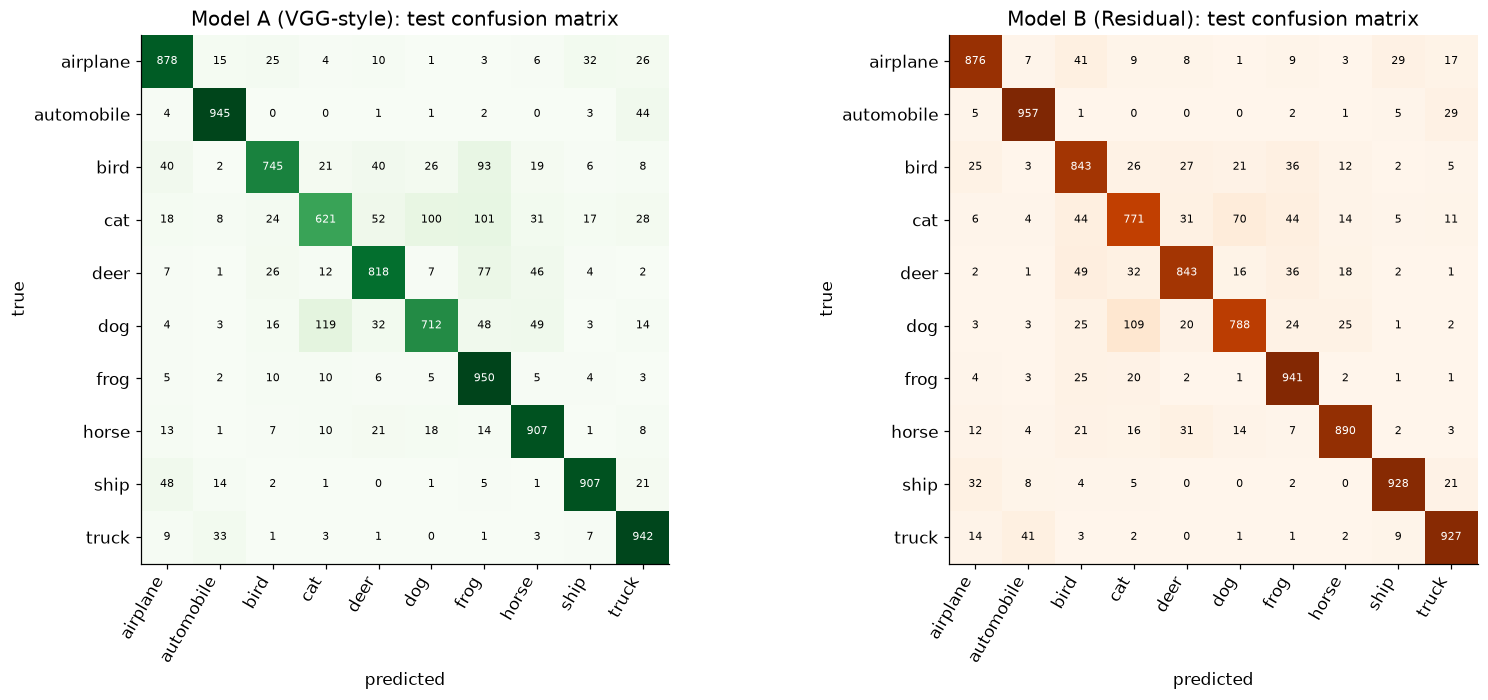

Model A (VGG-style) - three most-confused pairs:
   cat <-> dog: 219 errors
   cat <-> frog: 111 errors
   bird <-> frog: 103 errors
Model B (Residual) - three most-confused pairs:
   cat <-> dog: 179 errors
   bird <-> deer: 76 errors
   automobile <-> truck: 70 errors


In [33]:
def plot_confusion(ax, cm, title, cmap):
    ax.imshow(cm, cmap=cmap)
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xticklabels(CLASS_NAMES, rotation=60, ha="right"); ax.set_yticklabels(CLASS_NAMES)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > cm.max() * 0.5 else "black")
    ax.set_title(title); ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.grid(False)

def top_confused_pairs(cm, k=3):
    pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j] + cm[j, i])) for i in range(10) for j in range(i + 1, 10)]
    return sorted(pairs, key=lambda t: -t[2])[:k]

cms = {n: confusion_matrix(y_test, y_pred[n]) for n in probs}
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, n, cmap in zip(axes, probs, ["Greens", "Oranges"]):
    plot_confusion(ax, cms[n], f"{DISPLAY_NAME[n]}: test confusion matrix", cmap)
plt.tight_layout(); plt.show()

for n in probs:
    print(DISPLAY_NAME[n], "- three most-confused pairs:")
    for a, b, c in top_confused_pairs(cms[n]): print(f"   {a} <-> {b}: {c} errors")

**Reading the matrices (edit after your run).**

> *Model A (VGG-style): The three most-confused pairs are cat ↔ dog (219 errors), cat ↔ frog (111 errors), and bird ↔ frog (103 errors).*


>*Model B (Residual): The three most-confused pairs are cat ↔ dog (179 errors), bird ↔ deer (76 errors), and automobile ↔ truck (70 errors).*

<a id="w3-5"></a>
### 3.5 Comparison table

Accuracy alone does not tell the whole story: a model that is 3 points better but needs far more parameters or time may not be the better engineering choice.

,Model A (VGG-style),Model B (Residual)
test accuracy,0.842500,0.876400
test loss,0.483093,0.386510
total parameters,815914.000000,1246154.000000
trainable parameters,815018.000000,1243402.000000
time per epoch (s),51.650386,178.997117
epochs run,60.000000,58.000000
epochs to best val score,43.000000,53.000000
best val accuracy,0.857400,0.880400


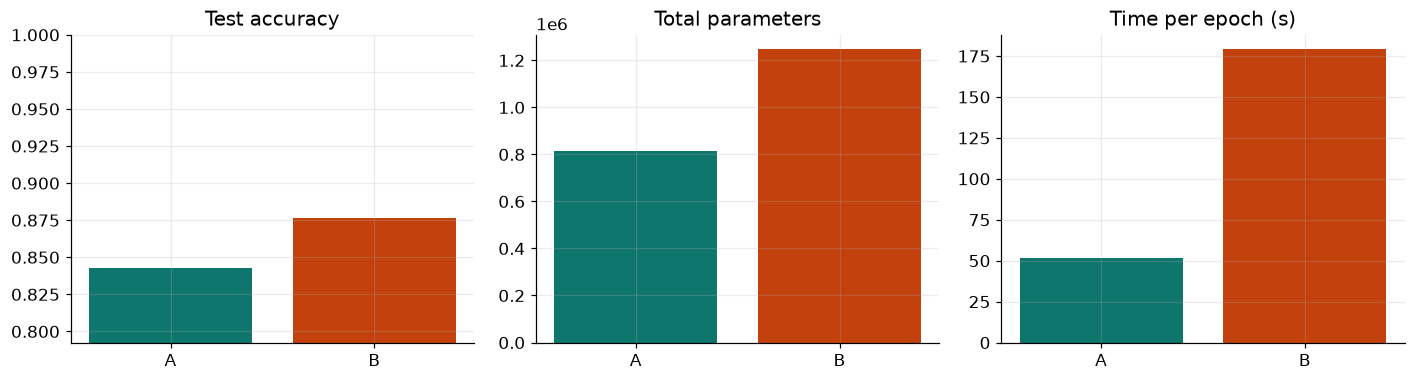

In [34]:
def comparison_table():
    rows = {}
    for n, hist in [("model_a", hist_a), ("model_b", hist_b)]:
        m = keras.models.load_model(artifact(f"{n}.keras"))
        total, trainable = param_counts(m); s = summarize_history(hist)
        rows[DISPLAY_NAME[n]] = {
            "test accuracy": TEST_RESULTS[n]["test_accuracy"], "test loss": TEST_RESULTS[n]["test_loss"],
            "total parameters": total, "trainable parameters": trainable,
            "time per epoch (s)": s["mean time per epoch (s)"], "epochs run": s["epochs run"],
            "epochs to best val score": s["epoch of best val accuracy"], "best val accuracy": s["best val accuracy"]}
    return pd.DataFrame(rows)

comp = comparison_table()
display(comp.style.format({"test accuracy": "{:.2%}", "test loss": "{:.4f}", "total parameters": "{:,.0f}",
                           "trainable parameters": "{:,.0f}", "time per epoch (s)": "{:.1f}", "epochs run": "{:.0f}",
                           "epochs to best val score": "{:.0f}", "best val accuracy": "{:.2%}"}))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
names = list(comp.columns); cols = [COLORS["model_a"], COLORS["model_b"]]
for ax, row, title in zip(axes, ["test accuracy", "total parameters", "time per epoch (s)"],
                          ["Test accuracy", "Total parameters", "Time per epoch (s)"]):
    ax.bar(["A", "B"], comp.loc[row].values, color=cols); ax.set_title(title)
axes[0].set_ylim(comp.loc["test accuracy"].min() - 0.05, 1.0)
plt.tight_layout(); plt.show()

<a id="w3-6"></a>
### 3.6 Error analysis

Numbers say *how often* a model fails; images show *how*. We display the **10 most confidently wrong** test images for each model, because confident mistakes are the most informative: they reveal ambiguous images, label noise or features the network misreads.

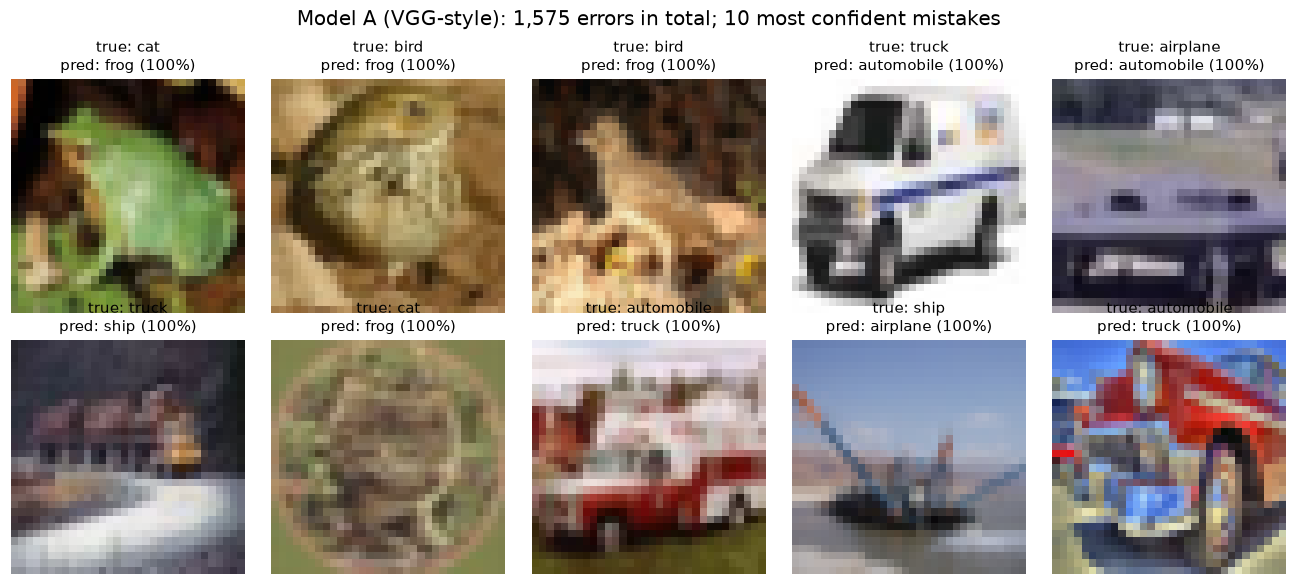

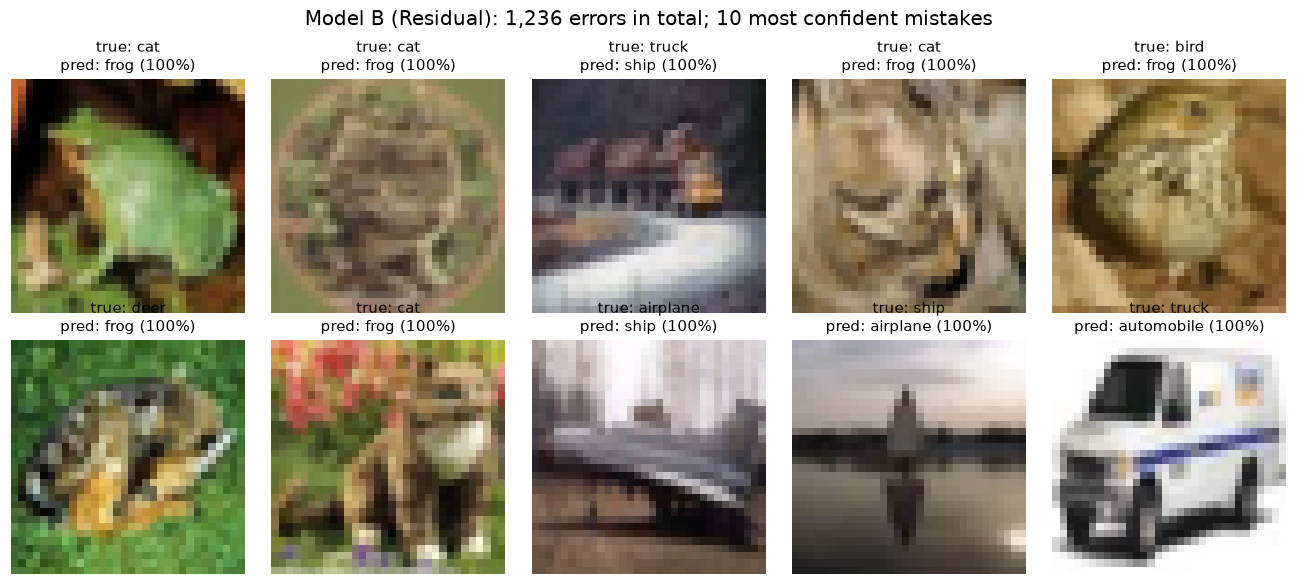

In [35]:
def show_errors(name, n_show=10):
    p, pred = probs[name], y_pred[name]
    wrong = np.where(pred != y_test)[0]
    worst = wrong[np.argsort(-p[wrong, pred[wrong]])][:n_show]
    fig, axes = plt.subplots(2, 5, figsize=(12, 5.4))
    for ax, i in zip(axes.ravel(), worst):
        ax.imshow(x_test_raw[i]); ax.axis("off")
        ax.set_title(f"true: {CLASS_NAMES[y_test[i]]}\npred: {CLASS_NAMES[pred[i]]} ({p[i, pred[i]]:.0%})", fontsize=10)
    fig.suptitle(f"{DISPLAY_NAME[name]}: {len(wrong):,} errors in total; 10 most confident mistakes", fontsize=13)
    plt.tight_layout(); plt.show()

for n in probs: show_errors(n)

**Error patterns (edit after your run).**

> *Model A often confuses cats and dogs due to similar fur, poses, and backgrounds. Model B reduces these errors but still struggles with visually similar classes, such as birds and deer or cars and trucks. Overall, Model B makes fewer errors but does not eliminate the same visual challenges.*

<a id="w3-7"></a>
### 3.7 Comparison with the expected targets

The brief expects roughly **85%** for Model A and **88–90%** for Model B. These are approximate targets; what counts is that we report what we measured and explain any gap.

In [36]:
targets = {"model_a": (85.0, 85.0), "model_b": (88.0, 90.0)}
rows = []
for n, (lo, hi) in targets.items():
    acc = TEST_RESULTS[n]["test_accuracy"] * 100
    gap = acc - lo if acc < lo else (acc - hi if acc > hi else 0.0)
    rows.append({"model": DISPLAY_NAME[n], "target": f"{lo:.0f}%" if lo == hi else f"{lo:.0f}-{hi:.0f}%",
                 "measured": f"{acc:.2f}%", "gap to target range (points)": f"{gap:+.2f}"})
display(pd.DataFrame(rows).set_index("model"))
diff = (TEST_RESULTS["model_b"]["test_accuracy"] - TEST_RESULTS["model_a"]["test_accuracy"]) * 100
print(f"Model B minus Model A: {diff:+.2f} accuracy points.")

,target,measured,gap to target range (points)
model,,,
Model A (VGG-style),85%,84.25%,-0.75
Model B (Residual),88-90%,87.64%,-0.36


Model B minus Model A: +3.39 accuracy points.


**Explaining the gap** Useful points to consider:

> - *Training length:* did early stopping end training before the learning rate had decayed fully?
> - *Capacity and depth:* is Model B's advantage consistent with skip connections easing optimisation, or is it also just more parameters (1.25M vs 0.82M)?
> - *Regularisation:* are dropout and augmentation strong enough or too strong for models this small?
> - *Randomness:* one run per model has seed-to-seed variation of a few tenths of a point, so small gaps are not conclusive.
> - *Limitations:* 32×32 resolution, a single seed, no hyperparameter search.

<a id="w3-8"></a>
### 3.8 Report draft outline

The report is 8–12 pages. Sections marked **full** must already be written in the Week 3 draft.

| Section | Pages | Draft status | Source in this notebook |
|---|---|---|---|
| 1. Introduction | 0.5–1 | outline | Project at a glance |
| 2. Dataset | 1 | **full** | 1.2–1.6 |
| 3. Architectures with diagrams | 2–3 | **full** | 1.7, 1.8, 2.5–2.7 and `model_b_architecture.png` |
| 4. Training setup | 1 | **full** | 2.1 |
| 5. Results | 2 | outline | 2.3, 3.1–3.4 |
| 6. Comparison | 1 | outline | 3.5 |
| 7. Discussion (why B differs from A, gap from targets, limitations) | 1–2 | outline | 3.6, 3.7 |
| 8. Conclusion | 0.5 | outline | Take-aways of each checkpoint |

<a id="cp3"></a>
### Checkpoint 3 summary

**Delivered**
- **Model B trained** with the identical recipe; `model_b.keras` saved, curves and diagnosis provided.
- **One-time test evaluation** of both saved models (accuracy and loss), cached in `test_results.json`.
- Per-class precision, recall and F1, 10×10 confusion matrices and the three most-confused pairs for each model.
- Comparison table (accuracy, loss, parameters, time per epoch, epochs to best validation score).
- Error analysis with the most confident mistakes, a comparison with the 85% and 88–90% targets, and the report draft outline.

**Take-aways**
- Fair comparison = same data, same recipe, same seed, one test evaluation.
- Look beyond accuracy: parameters, training time and class-level behaviour all matter.

**Progress note (edit before submitting).** *Report both test accuracies, the most-confused pairs, whether the targets were reached, and any retraining done after seeing test results (the rule requires saying so).*

<a id="week4"></a>
<div style="background:#C2410C;color:white;padding:20px 26px;border-radius:12px">
<h1 style="margin:0;color:white">Week 4 · Final report, presentation and submission</h1>
<p style="margin:6px 0 0 0;font-size:16px">Final package · 40% of the grade</p>
</div>

### What we do this week

The experiments are finished; Week 4 turns the checkpoints into a package that someone else can run, understand and trust:

1. confirm the notebook runs from a fresh runtime and that the **saved models reproduce the reported test accuracy**,
2. add a **live prediction demo** on new photos that are not from CIFAR-10,
3. list the changes made in response to feedback from Checkpoints 1–3,
4. finish the 8–12 page report and plan the 10-minute presentation (every member presents one part),
5. optionally run the CIFAR-100 transfer-learning extension (+5% bonus), then complete the contribution log and submission checklist.

<a id="w4-1"></a>
### 4.1 Reproducibility check

**Clean run.** Use **Runtime → Restart session and run all** (Jupyter: *Restart Kernel and Run All Cells*). With `FORCE_RETRAIN = False` the notebook reuses the saved models and histories, so a full re-run takes minutes; set it to `True` once to prove that training itself reproduces.

**Saved models reproduce the reported accuracy.** The cell below reloads `model_a.keras` and `model_b.keras` from disk and compares a fresh evaluation with the numbers reported in Week 3. This verifies the files; it is not used to tune anything.

In [37]:
rows = []
for n in ["model_a", "model_b"]:
    m = keras.models.load_model(artifact(f"{n}.keras"))
    _, acc = m.evaluate(x_test, y_test, batch_size=256, verbose=0)
    reported = TEST_RESULTS[n]["test_accuracy"]
    rows.append({"model": DISPLAY_NAME[n], "reported (Week 3)": reported, "re-loaded now": acc,
                 "difference": abs(acc - reported), "reproduced": abs(acc - reported) < 1e-4})
repro = pd.DataFrame(rows).set_index("model")
display(repro.style.format({"reported (Week 3)": "{:.4%}", "re-loaded now": "{:.4%}", "difference": "{:.2e}"}))
assert repro["reproduced"].all(), "Saved models do not reproduce the reported accuracy"
print("Both saved models load and reproduce the reported test accuracy.")

,reported (Week 3),re-loaded now,difference,reproduced
model,,,,
Model A (VGG-style),84.2500%,84.2500%,0.00e+00,True
Model B (Residual),87.6400%,87.6400%,0.00e+00,True


Both saved models load and reproduce the reported test accuracy.


<a id="w4-2"></a>
### 4.2 Live prediction demo on new images

**Rules for the demo images:** photos found or taken by the group, **not** from CIFAR-10. Put them in the `demo_images/` folder (or upload them when prompted in Colab). Each photo is centre-cropped to a square, resized to 32×32, scaled to [0, 1] like the training data, and classified by **both** models. The output lists each model's top-3 predictions.

**Expect surprises, and discuss them.** The models only know ten classes at 32×32 resolution, so a photo of a bicycle will still be forced into one of the ten classes, often with a confident but meaningless answer. That is a real limitation worth mentioning in the talk.

In [38]:
from PIL import Image, ImageOps

DEMO_DIR = "demo_images"; os.makedirs(DEMO_DIR, exist_ok=True)
IMG_EXT = (".jpg", ".jpeg", ".png", ".webp", ".bmp")
def demo_files(): return sorted(f for f in os.listdir(DEMO_DIR) if f.lower().endswith(IMG_EXT))

if not demo_files():
    try:
        from google.colab import files
        print("No demo images found. Please choose 3-6 photos (not from CIFAR-10).")
        for fname, content in files.upload().items():
            open(os.path.join(DEMO_DIR, fname), "wb").write(content)
    except ImportError:
        print(f"No images in '{DEMO_DIR}/'. Add some photos there and re-run this cell.")

def to_model_input(path):
    img = ImageOps.fit(Image.open(path).convert("RGB"), (32, 32), Image.LANCZOS)   # centre-crop + resize
    return np.asarray(img, dtype="float32") / 255.0

def top3(model, x):
    p = model.predict(x[None], verbose=0)[0]
    return [(CLASS_NAMES[i], float(p[i])) for i in np.argsort(-p)[:3]]

demo_models = {n: keras.models.load_model(artifact(f"{n}.keras")) for n in ["model_a", "model_b"]}
for fname in demo_files():
    x = to_model_input(os.path.join(DEMO_DIR, fname))
    fig, ax = plt.subplots(1, 3, figsize=(10, 2.8), gridspec_kw={"width_ratios": [1, 1, 2.4]})
    ax[0].imshow(Image.open(os.path.join(DEMO_DIR, fname)).convert("RGB")); ax[0].set_title("original"); ax[0].axis("off")
    ax[1].imshow(x, interpolation="nearest"); ax[1].set_title("what the model sees\n(32×32)"); ax[1].axis("off")
    lines = []
    for n, m in demo_models.items():
        lines.append(DISPLAY_NAME[n] + ":  " + "   ".join(f"{c} {p:.0%}" for c, p in top3(m, x)))
    ax[2].text(0, 0.5, "\n\n".join(lines), va="center", fontsize=10, family="monospace", wrap=True); ax[2].axis("off")
    fig.suptitle(fname, fontsize=11); plt.tight_layout(); plt.show()

No images in 'demo_images/'. Add some photos there and re-run this cell.


<a id="w4-3"></a>
### 4.3 Feedback from Checkpoints 1–3 and how we addressed it

*Fill this table with the instructor's comments and the changes made, then keep it as an appendix in the report.*

| Checkpoint | Feedback received | Change made | Where |
|---|---|---|---|
| 1 (data and Model A) | | | |
| 2 (training A, building B) | | | |
| 3 (training B, evaluation) | | | |

<a id="w4-4"></a>
### 4.4 Final report map (8–12 pages)

Each report section is built from material already produced in this notebook. Export figures with `plt.savefig("name.png", dpi=200, bbox_inches="tight")` if you need files.

| Report section | Content to include | Notebook source |
|---|---|---|
| Introduction | question, motivation, what was built | Project at a glance |
| Dataset | CIFAR-10, split with class counts, preprocessing, augmentation | 1.2–1.6 |
| Architectures | both diagrams (use `model_b_architecture.png`), layer tables, parameter derivations, why the 1×1 shortcut matches the stride | 1.7, 1.8, 2.5–2.7 |
| Training setup | recipe table, callbacks, seed, hardware | 2.1 |
| Results | learning curves, best validation scores, test accuracy and loss, per-class metrics, confusion matrices | 2.3, 3.1–3.4 |
| Comparison | comparison table and charts | 3.5 |
| Discussion | **why B differs from A**, gap from the 85% and 88–90% targets, error analysis, limitations | 3.6, 3.7 |
| Conclusion | answer to the project question, what to try next | take-aways |

**Discussion checklist**
- Why does Model B differ from Model A? (skip connections, depth, global average pooling, parameter count)
- Where and why do both models fail? (class pairs, 32×32 resolution)
- What are the limitations? (one seed, no hyperparameter search, small images, tuning only on validation)

<a id="w4-5"></a>
### 4.5 Presentation plan (10 minutes)

Every member presents one part, and questions go to **individual members**, so everyone must understand every part.

| Min | Part | Content | Presenter |
|---|---|---|---|
| 0–1 | Problem and set-up | the question, CIFAR-10, the fair-comparison rules | Member 1 |
| 1–3 | Data and Model A | split, augmentation, VGG-style design, 815,914 parameters | Member 1 / 2 |
| 3–5 | Model B | residual block, why the shortcut matches the stride, 1,246,154 parameters | Member 2 |
| 5–7 | Results | curves, test accuracy, confusion matrices, comparison table | Member 2 / 3 |
| 7–9 | **Live demo** | new photos through both models, top-3 predictions | Member 3 |
| 9–10 | Conclusion | what we learned, limitations, next steps | Member 3 |

**Questions to prepare for:** What does the skip connection do? Why can the test set only be used once? Why does augmentation lower training accuracy? Why is `cat` vs `dog` the hardest pair? What does batch normalisation add to the parameter count?

<a id="w4-6"></a>
### 4.6 Bonus: transfer learning from CIFAR-10 to CIFAR-100 (+5%)

**Idea.** CIFAR-100 has the same image size but 100 classes. The early layers of a trained network learn general features (edges, textures, shapes), so they should be a good starting point for a new task.

| Model | Description |
|---|---|
| Model 1 | the trained 10-class model (we use Model B, `model_b.keras`) |
| Model 2 | same network with a **new 100-class output layer**, all other layers initialised from Model 1 (transfer) |
| Model 3 | same architecture with 100 classes, trained **from scratch** |

Models 2 and 3 are compared on accuracy, precision, recall and F1 (macro-averaged over the 100 classes) on the CIFAR-100 test set, using the same recipe, split logic and seed. Set `FREEZE_BACKBONE = True` to train only the new output layer instead of fine-tuning everything.

**Trade-off.** Fine-tuning all layers usually gives the best accuracy but needs more care (a pre-trained network can be disturbed by large early updates); freezing is faster and safer but limits what the network can adapt.

Set `RUN_EXTENSION = True` in cell 1.1 to run it (expect another 40–80 minutes on a free GPU).

In [39]:
FREEZE_BACKBONE = False

if not RUN_EXTENSION:
    print("Extension skipped (RUN_EXTENSION = False).")
else:
    (x100_full, y100_full), (x100_test_raw, y100_test) = keras.datasets.cifar100.load_data(label_mode="fine")
    y100_full, y100_test = y100_full.ravel(), y100_test.ravel()
    tr, va = train_test_split(np.arange(len(y100_full)), test_size=5000, stratify=y100_full, random_state=SEED)
    x100_tr, y100_tr = preprocess(x100_full[tr]), y100_full[tr]
    x100_va, y100_va = preprocess(x100_full[va]), y100_full[va]
    x100_te = preprocess(x100_test_raw)
    data100 = (x100_tr, y100_tr, x100_va, y100_va)
    print("CIFAR-100 split:", x100_tr.shape, x100_va.shape, x100_te.shape)

    # Model 2: transfer. Keep everything up to (and including) the dropout layer, replace the 10-way output layer.
    keras.utils.set_random_seed(SEED)
    base = keras.models.load_model(artifact("model_b.keras"))
    new_out = layers.Dense(100, activation="softmax", name="fc2_100")(base.get_layer("drop_head").output)
    model2 = keras.Model(base.input, new_out, name="model2_transfer")
    if FREEZE_BACKBONE:
        for l in model2.layers[:-1]: l.trainable = False
    COLORS.update({"ext_model2": "#0F766E", "ext_model3": "#C2410C"})
    DISPLAY_NAME.update({"ext_model2": "Model 2 (transfer)", "ext_model3": "Model 3 (scratch)"})
    hist2 = train_model(model2, "ext_model2", data100)

    # Model 3: same architecture, 100 classes, random initialisation.
    keras.utils.set_random_seed(SEED)
    model3 = build_model_b(num_classes=100)
    hist3 = train_model(model3, "ext_model3", data100)

    rows = {}
    for name, hist in [("ext_model2", hist2), ("ext_model3", hist3)]:
        m = keras.models.load_model(artifact(f"{name}.keras"))
        pred = m.predict(x100_te, batch_size=256, verbose=0).argmax(1)
        p, r, f, _ = precision_recall_fscore_support(y100_test, pred, average="macro", zero_division=0)
        rows[DISPLAY_NAME[name]] = {"accuracy": float((pred == y100_test).mean()), "precision (macro)": p,
                                    "recall (macro)": r, "F1 (macro)": f,
                                    "epochs run": len(hist["loss"]), "time per epoch (s)": float(np.mean(hist["epoch_time"]))}
    ext = pd.DataFrame(rows)
    display(ext.style.format("{:.4f}"))
    ext.loc[["accuracy", "precision (macro)", "recall (macro)", "F1 (macro)"]].plot.bar(
        figsize=(8, 3.6), color=["#0F766E", "#C2410C"], rot=0, title="Transfer vs scratch on CIFAR-100 (test set)")
    plt.ylim(0, 1); plt.show()

Extension skipped (RUN_EXTENSION = False).


**Extension findings (edit after your run).** *State which model won on all four metrics, by how much, whether Model 2 also converged in fewer epochs, and why the CIFAR-10 features help (shared low-level visual features) or why they might not (different class semantics).*

<div style="background:#0B1F3A;color:white;padding:22px 28px;border-radius:12px">
<h2 style="margin:0;color:white">Conclusion</h2>
<p style="margin:8px 0 0 0;font-size:16px;color:#CBD5E1">We built two CNNs with different Keras APIs, trained them under identical conditions, evaluated them once on a held-out test set and compared them on accuracy, parameters, training time and class-level behaviour. Write the final answer to the project question here: what did the skip connections buy us, and at what cost?</p>
</div>